# 运费与地理关系分析

运费由什么决定：同州/跨州对比、各州运费差异与卖家地理分布的关系。

         件数   运费均值    货值均值  运费占货值%
same                              
跨州    70331  23.63  129.21    18.3
同州    39866  13.45  103.71    13.0


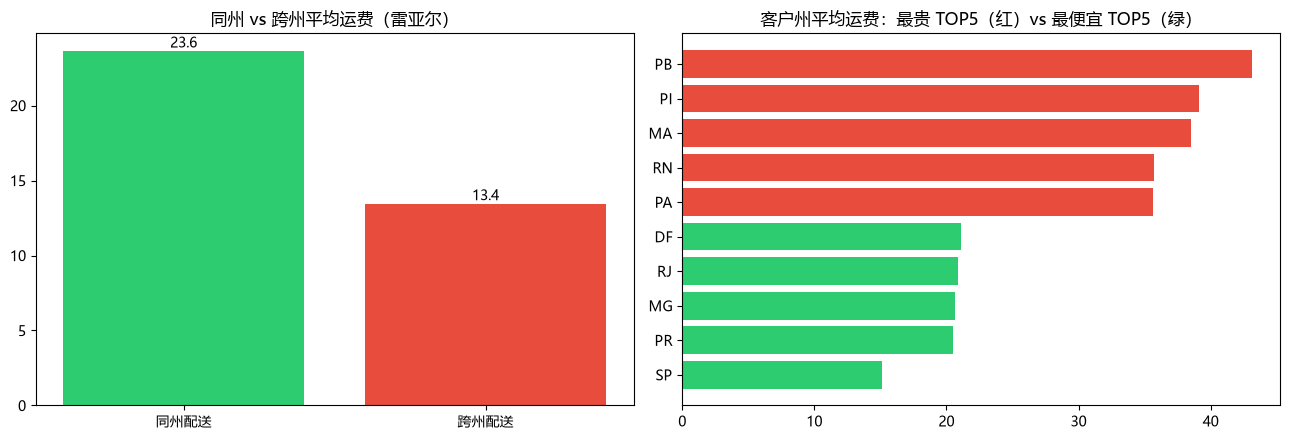

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

orders = pd.read_csv('data/orders_clean.csv', parse_dates=['order_purchase_timestamp'])
items = pd.read_csv('data/order_items_clean.csv')
sellers = pd.read_csv('data/sellers_clean.csv')
customers = pd.read_csv('data/customers_clean.csv')

o = orders[orders['order_status'] == 'delivered']
it2 = items.merge(o[['order_id', 'customer_id']], on='order_id')
it2['seller_state'] = it2['seller_id'].map(sellers.set_index('seller_id')['seller_state'])
it2['cust_state'] = it2['customer_id'].map(customers.set_index('customer_id')['customer_state'])
it2['same'] = it2['seller_state'] == it2['cust_state']

fr = it2.groupby('same').agg(件数=('price', 'size'), 运费均值=('freight_value', 'mean'),
                             货值均值=('price', 'mean'))
fr['运费占货值%'] = (fr['运费均值'] / fr['货值均值'] * 100).round(1)
print(fr.round(2).rename(index={True: '同州', False: '跨州'}).to_string())

fs = it2.groupby('cust_state').agg(运费=('freight_value', 'mean'), 件数=('price', 'size'))
fs = fs[fs['件数'] > 500]
top5 = fs.sort_values('运费', ascending=False).head(5)
low5 = fs.sort_values('运费').head(5)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(['同州配送', '跨州配送'], fr['运费均值'], color=['#2ecc71', '#e74c3c'])
axes[0].set_title('同州 vs 跨州平均运费（雷亚尔）')
for i, v in enumerate(fr['运费均值']):
    axes[0].text(i, v, f'{v:.1f}', ha='center', va='bottom')

both = pd.concat([top5, low5.iloc[::-1]])
colors = ['#e74c3c'] * 5 + ['#2ecc71'] * 5
axes[1].barh(both.index[::-1], both['运费'][::-1], color=colors[::-1])
axes[1].set_title('客户州平均运费：最贵 TOP5（红）vs 最便宜 TOP5（绿）')
plt.tight_layout(); plt.show()


## 结论

- **距离决定运费**：跨州运费均值 23.63（占货值 18.3%），同州仅 13.45（占 13.0%）。
- **南北差异悬殊**：运费最贵的州集中在北部/东北部（PB 43、PI 39、MA 38、RN 36、PA 36），最便宜的集中在卖家聚集的东南部（SP 15、PR 21、MG 21、RJ 21）。
- **根因在卖家分布**：卖家高度集中于圣保罗州，北部/东北部消费者承担约 3 倍运费，这很可能是边远地区订单密度低的原因——招募本地卖家是降低边远地区运费、激活需求的关键。

## 业务解读

- 运费占货值 18.3%（跨州）远高于成熟电商市场（<10%），运费是巴西电商最大的转化摩擦之一，也是免运费门槛设计的依据。
- 卖家 80%+ 集中在东南部（圣保罗及周边），形成双边市场冷启动的典型格局：运费 3 倍差异 → 北方/东北需求被抑制 → 更少卖家愿意服务北方 → 运费更贵的负循环。
- 打破循环的路径是**供给侧**：在东北部（PE/BA/CE）招募本地卖家，比补贴运费更可持续；Olist 实际上在 2018 年后也沿此方向扩张。
- 同州运费 13.45 的存在说明即使在州内也有基础物流成本，免运费策略应按「订单金额 > 同州运费 × N」设计门槛。

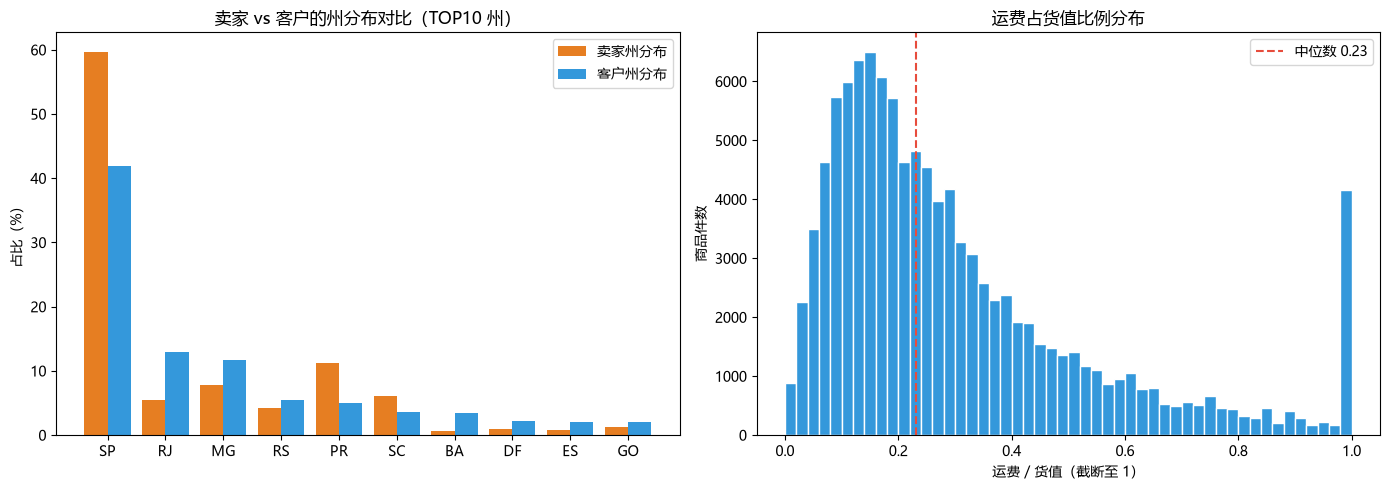

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ① 卖家州分布 vs 客户州分布对比（TOP10 州，占比%）
sel_dist = sellers['seller_state'].value_counts(normalize=True) * 100
cus_dist = customers['customer_state'].value_counts(normalize=True) * 100
top_states = cus_dist.head(10).index
xs = np.arange(len(top_states))
axes[0].bar(xs - .2, sel_dist.reindex(top_states).fillna(0).values, .4,
            label='卖家州分布', color='#e67e22')
axes[0].bar(xs + .2, cus_dist[top_states].values, .4,
            label='客户州分布', color='#3498db')
axes[0].set_xticks(xs, top_states)
axes[0].set_ylabel('占比（%）'); axes[0].set_title('卖家 vs 客户的州分布对比（TOP10 州）')
axes[0].legend()

# ② 运费/货值比直方图（截断至 1）
ratio = (it2['freight_value'] / it2['price']).clip(upper=1)
axes[1].hist(ratio, bins=50, color='#3498db', edgecolor='white')
axes[1].axvline(ratio.median(), color='#e74c3c', ls='--',
                label=f'中位数 {ratio.median():.2f}')
axes[1].set_xlabel('运费 / 货值（截断至 1）'); axes[1].set_ylabel('商品件数')
axes[1].set_title('运费占货值比例分布'); axes[1].legend()

plt.tight_layout()
plt.show()